# Which apps work through travel eSIMs: a first look

Travel eSIMs usually work as international roaming, so traffic exits to the internet in another country. This notebook shows how to read the dataset, where travel eSIM traffic exits, which services are restricted in the visited country itself, and how to reproduce every status from the raw OONI counters.

Data: Letsim (letsim.ru) and [OONI](https://ooni.org) measurements, 25 Sep – 24 Nov 2026. Archived release: [doi:10.5281/zenodo.24510796](https://doi.org/10.5281/zenodo.24510796). Page with findings (in Russian): https://letsim.ru/issledovaniya/prilozheniya-cherez-esim

*Disclosure: Letsim is a commercial travel eSIM provider that sells the plans discussed here.*

In [1]:
import glob
import pandas as pd
import matplotlib.pyplot as plt

def find(name):
    """Path to a dataset file on Kaggle (/kaggle/input/...) or in the current folder."""
    hits = glob.glob(f'/kaggle/input/**/{name}', recursive=True) or glob.glob(name)
    return hits[0]

read = lambda name: pd.read_csv(find(name), sep=';', encoding='utf-8-sig')

df = read('data.csv')            # destination x exit country
m = read('measurements.csv')     # raw OONI counters per country x service
SERVICES = ['google', 'youtube', 'whatsapp', 'telegram', 'instagram']
print(df.shape, m.shape)
df.head()

(206, 18) (285, 18)


,country_code,country_ru,world_region,exit_code,exit_country_ru,plans,local_breakout,via_esim_google,via_esim_youtube,via_esim_whatsapp,via_esim_telegram,via_esim_instagram,in_country_google,in_country_youtube,in_country_whatsapp,in_country_telegram,in_country_instagram,page_url
0,AU,Австралия,Океания,SG,Сингапур,"пакеты, безлимит",0,available,available,available,available,available,NaN,NaN,NaN,NaN,NaN,https://letsim.ru/esim/avstraliya
1,AU,Австралия,Океания,AU,Австралия,Premium,1,available,available,available,available,available,NaN,NaN,NaN,NaN,NaN,https://letsim.ru/esim/avstraliya
2,AT,Австрия,Европа,FR/NL/UK,"Франция, Нидерланды, Великобритания","пакеты, безлимит",0,available,available,available,available,available,NaN,NaN,NaN,NaN,NaN,https://letsim.ru/esim/avstriya
3,AZ,Азербайджан,СНГ и Кавказ,UK,Великобритания,"пакеты, безлимит",0,available,available,available,available,available,available,available,available,available,available,https://letsim.ru/esim/azerbaidzhan
4,AX,Аландские острова,Европа,NL/FR/US,"Нидерланды, Франция, США","пакеты, безлимит",0,available,available,available,available,available,NaN,NaN,NaN,NaN,NaN,https://letsim.ru/esim/alandskie-ostrova


## Where travel eSIM traffic exits to the internet

In [2]:
g = df.groupby('country_code')['local_breakout']
some_abroad, all_local, some_local = g.min() == 0, g.min() == 1, g.max() == 1
print(f'Destinations: {g.ngroups}')
print(f'At least one plan exits through another country: {some_abroad.sum()}')
print('All plans exit locally:', ', '.join(sorted(all_local[all_local].index)))
print('Local exit for some plans (incl. groups like FR/NL/UK):', ', '.join(sorted(some_local[some_local].index)))

Destinations: 196
At least one plan exits through another country: 190
All plans exit locally: BR, FR, GB, IL, NL, US
Local exit for some plans (incl. groups like FR/NL/UK): AU, BR, FR, GB, IL, JP, MY, NL, TH, US


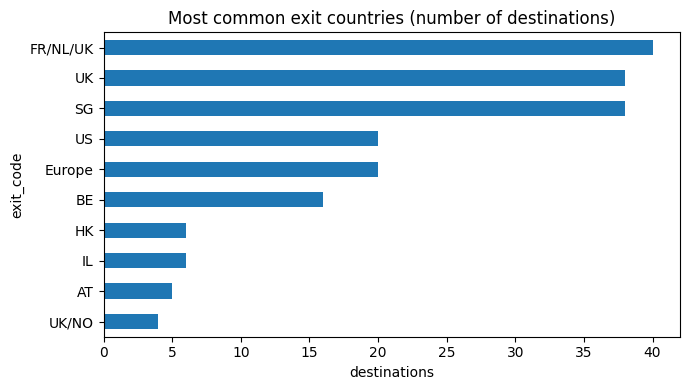

In [3]:
exits = df.drop_duplicates(['country_code', 'exit_code'])['exit_code'].value_counts().head(10)
exits.sort_values().plot.barh(figsize=(7, 4), title='Most common exit countries (number of destinations)')
plt.xlabel('destinations')
plt.tight_layout()
plt.show()

## Availability via the eSIM and in the visited country

`via_esim_*` — status in the exit country; `in_country_*` — status in the visited country itself (measured for the 40 most popular destinations). Statuses: `available`, `unstable`, `blocked`, `no_data`.

In [4]:
via = pd.DataFrame({s: df[f'via_esim_{s}'].value_counts() for s in SERVICES}).fillna(0).astype(int)
local_st = pd.DataFrame({s: df.drop_duplicates('country_code')[f'in_country_{s}'].value_counts() for s in SERVICES}).fillna(0).astype(int)
print('Via the eSIM (rows = destination x exit):')
display(via)
print('In the visited country (destinations measured):')
display(local_st)

Via the eSIM (rows = destination x exit):


,google,youtube,whatsapp,telegram,instagram
available,206,206,206,206,206


In the visited country (destinations measured):


,google,youtube,whatsapp,telegram,instagram
available,31,37,36,33,35
blocked,1,1,1,2,1
no_data,8,2,3,3,2
unstable,0,0,0,2,2


In [5]:
# Destinations where a service is restricted locally, and what is expected via the eSIM
rows = []
for s in SERVICES:
    bad = df[df[f'in_country_{s}'].isin(['blocked', 'unstable'])]
    for _, r in bad.iterrows():
        rows.append({'country': r.country_code, 'service': s, 'in_country': r[f'in_country_{s}'],
                     'exit': r.exit_code, 'via_esim': r[f'via_esim_{s}']})
pd.DataFrame(rows).sort_values(['in_country', 'country', 'service'])

,country,service,in_country,exit,via_esim
0,CN,google,blocked,HK,available
1,CN,google,blocked,SG,available
11,CN,instagram,blocked,HK,available
12,CN,instagram,blocked,SG,available
6,CN,telegram,blocked,HK,available
7,CN,telegram,blocked,SG,available
4,CN,whatsapp,blocked,HK,available
5,CN,whatsapp,blocked,SG,available
2,CN,youtube,blocked,HK,available
3,CN,youtube,blocked,SG,available


## Reproduce every status from the raw OONI counters (rules v1)

`ok_rate = ok / (measurements − failures)`; **available** — at least 30 measurements, ok_rate ≥ 0.9 and confirmed blocks < 1 %; **blocked** — confirmed > 10 % or ok_rate < 0.6; **unstable** — in between; **no_data** — fewer than 30 measurements.

In [6]:
def classify(r):
    n = r.measurement_count
    if pd.isna(n) or n < 30:
        return 'no_data'
    valid = max(n - (r.failure_count or 0), 1)
    ok, conf = r.ok_count / valid, r.confirmed_count / valid
    if conf > 0.1 or ok < 0.6:
        return 'blocked'
    return 'available' if ok >= 0.9 and conf < 0.01 else 'unstable'

m['rules'] = m.apply(classify, axis=1)
print('Mismatches with the status column:', (m['rules'] != m['status']).sum(), 'of', len(m))
m.groupby(['scope', 'status']).size().unstack(fill_value=0)

Mismatches with the status column: 0 of 285


status,available,blocked,no_data,unstable
scope,,,,
destination,172,6,18,4
exit,85,0,0,0


## Limitations, license, citation

An inference from plan routing and measurements, not an in-trip test of a specific eSIM. The OONI WhatsApp test checks the app, registration and web endpoints, not calls; website checks do not measure video speed.

License: CC BY-NC-SA 4.0 (as OONI data). Cite as: *Letsim (letsim.ru). Which apps work through travel eSIMs: 196 countries. 2026. doi:10.5281/zenodo.24510796. Measurement data: OONI, ooni.org.*